# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 68.6 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
SEARCHES = {
    "bicycle": [
        "bicycle real photograph",
        "bicycle parked street photo",
        "person riding bicycle photo",
    ],
    "motorcycle": [
        "motorcycle real photograph",
        "motorcycle parked street photo",
        "person riding motorcycle photo",
    ],
    "bus": [
        "city bus real photograph",
        "bus parked street photo",
        "bus driving road photo",
    ],
}

SEARCHES

{'bicycle': ['bicycle real photograph',
  'bicycle parked street photo',
  'person riding bicycle photo'],
 'motorcycle': ['motorcycle real photograph',
  'motorcycle parked street photo',
  'person riding motorcycle photo'],
 'bus': ['city bus real photograph',
  'bus parked street photo',
  'bus driving road photo']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Problema y estrategia de búsqueda:**

Mi objetivo es clasificar fotografías de tres tipos de vehículos:
bicicletas, motocicletas y buses.

Espero que el modelo utilice características como la forma del vehículo,
el tamaño de la carrocería, las ruedas, las ventanas y la presencia de
motor o pedales. Las bicicletas y motocicletas pueden ser más difíciles
de distinguir porque ambas suelen tener dos ruedas.

En las búsquedas podrían aparecer dibujos, juguetes, logos, imágenes
con varios vehículos o fotografías cuyo objeto principal no corresponda
a la clase indicada. Revisaré estos casos antes de entrenar.

Un posible sesgo sería que los buses aparezcan principalmente en
carreteras y las bicicletas en fondos blancos. El modelo podría aprender
a reconocer el fondo en lugar del vehículo. También podría existir
data leakage si fotografías duplicadas o casi idénticas aparecen en
entrenamiento y prueba.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bicycle ===
Buscando: 'bicycle real photograph'
  Total guardadas hasta ahora: 33
Buscando: 'bicycle parked street photo'
  Total guardadas hasta ahora: 67
Buscando: 'person riding bicycle photo'
  Total guardadas hasta ahora: 99

=== motorcycle ===
Buscando: 'motorcycle real photograph'
  Total guardadas hasta ahora: 33
Buscando: 'motorcycle parked street photo'
  Total guardadas hasta ahora: 65
Buscando: 'person riding motorcycle photo'
  Total guardadas hasta ahora: 99

=== bus ===
Buscando: 'city bus real photograph'
  Total guardadas hasta ahora: 32
Buscando: 'bus parked street photo'
  Total guardadas hasta ahora: 66
Buscando: 'bus driving road photo'
  Total guardadas hasta ahora: 95

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 99, 'bus': 95, 'motorcycle': 99}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


In [9]:
count_images(RAW_DIR)

{'bicycle': 99, 'bus': 95, 'motorcycle': 99}

# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

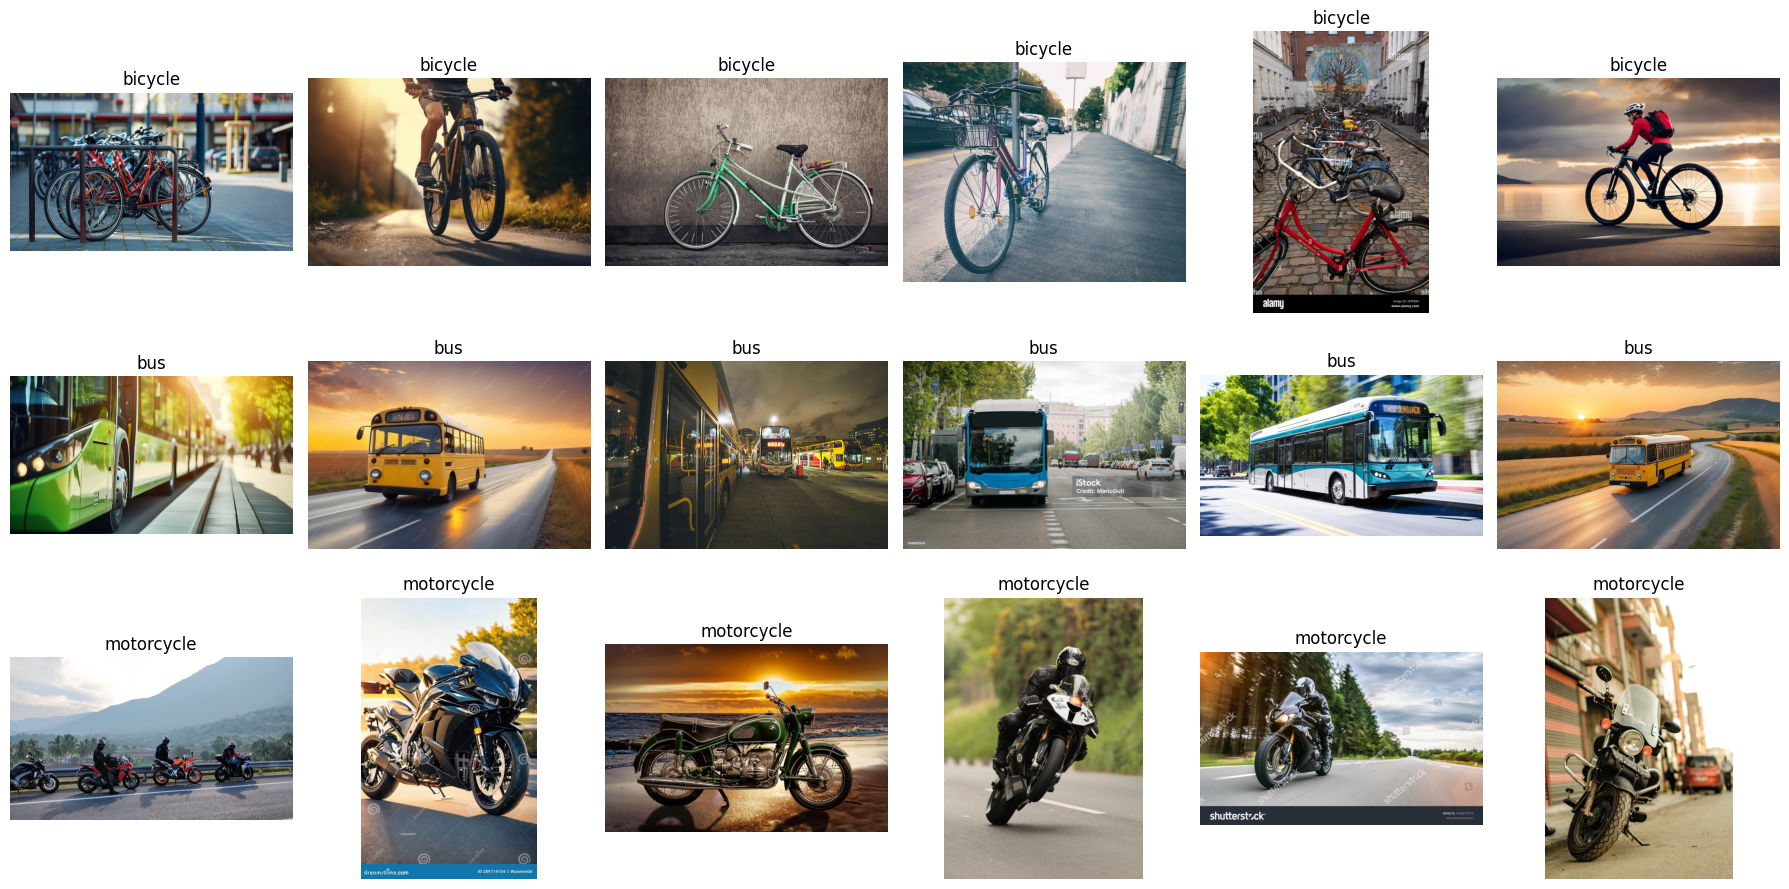

In [10]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.


**Checkpoint del dataset:**

El dataset contiene **289 imágenes**, distribuidas así:

| Clase | Cantidad |
|---|---:|
| bicycle | 98 |
| bus | 94 |
| motorcycle | 97 |

Las clases están razonablemente balanceadas: la diferencia entre
la clase con más imágenes y la de menos imágenes es de cuatro.

La validación técnica encontró **0 imágenes inválidas**, por lo
que no se eliminaron archivos por errores de decodificación.
Los conteos coinciden con los obtenidos después de la descarga,
por lo que no se registra una reducción por limpieza manual.

En la muestra revisada, los vehículos corresponden a las clases
indicadas. El problema de calidad más visible es la presencia de
**marcas de agua y texto de bancos de imágenes** en varias fotografías.
También aparecen imágenes con apariencia de ilustración o render,
que conviene revisar porque el objetivo es clasificar fotografías.

Antes de dividir el dataset, debo revisar estos archivos y eliminar
los que no cumplan el criterio definido. La inspección de esta muestra
no garantiza que todas las imágenes del conjunto sean correctas.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [11]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 69, 'bus': 66, 'motorcycle': 69}
validation {'bicycle': 14, 'bus': 14, 'motorcycle': 14}
test {'bicycle': 16, 'bus': 15, 'motorcycle': 16}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:**

Usar repetidamente el conjunto de prueba para escoger épocas,
learning rate o capas a descongelar hace que las decisiones se
adapten indirectamente a ese conjunto. Por eso, su resultado deja
de representar una evaluación independiente y puede ser demasiado
optimista.

Los pesos se aprenden con entrenamiento, las decisiones se toman
con validación y el conjunto de prueba se reserva para evaluar
el desempeño final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [12]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 204 files belonging to 3 classes.
Found 42 files belonging to 3 classes.
Found 47 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [13]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción antes de entrenar:**

Espero que el accuracy de entrenamiento aumente durante las
primeras épocas, porque la base preentrenada ya contiene
características visuales útiles y solo se entrenará el clasificador.

Una señal de overfitting sería que el accuracy de entrenamiento
continúe aumentando mientras el de validación se estanca o
disminuye y la pérdida de validación aumenta.

In [14]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.4167 - loss: 1.1268 - val_accuracy: 0.8333 - val_loss: 0.7658
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.7892 - loss: 0.6648 - val_accuracy: 0.9762 - val_loss: 0.4278
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.9412 - loss: 0.4145 - val_accuracy: 0.9762 - val_loss: 0.2619
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.9608 - loss: 0.2688 - val_accuracy: 0.9762 - val_loss: 0.1783
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.9657 - loss: 0.2155 - val_accuracy: 0.9762 - val_loss: 0.1360
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9559 - loss: 0.1841 - val_accuracy: 0.9762 - val_loss: 0.1142
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.9608 - loss: 0.1674 - val_accuracy: 0.9762 - val_loss: 0.1072
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9657 - loss: 0.1525 - val_accuracy: 0.9762 - val_loss: 0.1014
Epoch 9/

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

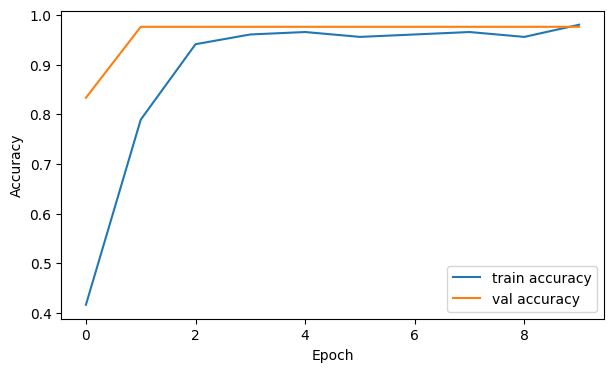

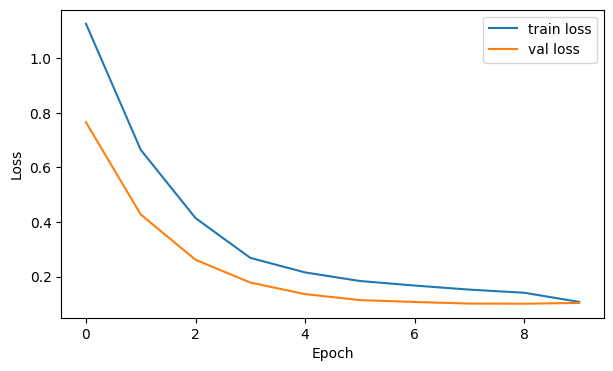

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [x] 3 clases definidas.
- [x] Términos de búsqueda documentados.
- [x] Imágenes descargadas.
- [x] Dataset inspeccionado mediante una muestra de 18 imágenes y validado técnicamente; se eliminaron 0 archivos inválidos.
- [ ] Separación `train / validation / test`.
- [ ] EfficientNetB0 con pesos de ImageNet.
- [ ] Backbone congelado.
- [ ] Nueva cabeza de clasificación.
- [ ] Al menos un entrenamiento completado.
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [16]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        16
         bus      1.000     1.000     1.000        15
  motorcycle      1.000     1.000     1.000        16

    accuracy                          1.000        47
   macro avg      1.000     1.000     1.000        47
weighted avg      1.000     1.000     1.000        47



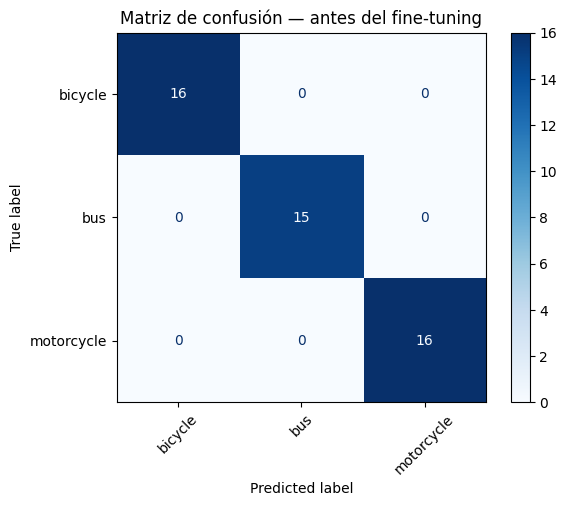

In [17]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

## Respuestas

### 1. ¿Cuál clase obtuvo mejores resultados?

**Respuesta:**

La clase **bus** obtuvo los mejores resultados, con precision,
recall y F1-score de **1.000**. El modelo clasificó correctamente
sus **15 imágenes**, sin confundirlas con otras clases ni asignar
incorrectamente otras imágenes a esta categoría.

### 2. ¿Cuál fue la principal confusión?

**Respuesta:**

La única confusión fue una imagen de **bicycle** clasificada como
**motorcycle**. De las 16 bicicletas, el modelo identificó
correctamente 15.

Esta confusión podría relacionarse con características visuales
compartidas, como las dos ruedas y el manubrio. Sin embargo, es
necesario observar la imagen para proponer una causa más precisa.

### 3. ¿La accuracy global oculta algún problema por clase?

**Respuesta:**

La accuracy global fue de **97.87 %**, correspondiente a
**46 aciertos de 47 imágenes**. Aunque es alta, no muestra por sí
sola la diferencia entre las clases.

La clase bicycle tuvo un recall de **0.938**, porque una bicicleta
no fue reconocida correctamente. La clase motorcycle tuvo una
precision de **0.941**, porque recibió esa predicción incorrecta.

No se observa un problema grave por clase en esta evaluación,
pero el conjunto de prueba es pequeño y estos resultados no
garantizan el mismo desempeño en todas las imágenes nuevas.

### 4. ¿Qué cambiarías primero en el dataset antes de cambiar el modelo?

**Respuesta:**

Primero mejoraría la calidad y diversidad de las imágenes de
entrenamiento, especialmente de bicicletas y motocicletas.
Revisaría las etiquetas, los duplicados, las marcas de agua y
las imágenes con apariencia de ilustración o render.

También incorporaría fotografías con distintos ángulos, fondos
e iluminación para que el modelo aprenda características del
vehículo y dependa menos del contexto.

Estos cambios se comprobarían mediante validación, sin modificar
el conjunto de prueba ni utilizarlo para escoger el entrenamiento.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [18]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


**Justificación:**

Elegí adaptar las últimas 20 capas como punto de partida,
siguiendo la sugerencia del taller. Esto permite ajustar una
parte final de la red sin modificar todos los pesos preentrenados.

Mantengo congeladas las capas BatchNormalization y comprobaré
el efecto del ajuste mediante las métricas de validación.

## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [19]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping_ft],
)

Epoch 1/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 46s 4s/step - accuracy: 0.9608 - loss: 0.1347 - val_accuracy: 0.9762 - val_loss: 0.0975
Epoch 2/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step - accuracy: 0.9853 - loss: 0.0985 - val_accuracy: 0.9762 - val_loss: 0.0944
Epoch 3/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.9755 - loss: 0.1076 - val_accuracy: 0.9762 - val_loss: 0.0913
Epoch 4/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.9853 - loss: 0.0909 - val_accuracy: 0.9762 - val_loss: 0.0882
Epoch 5/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.9755 - loss: 0.1101 - val_accuracy: 0.9762 - val_loss: 0.0868


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [20]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 1.0000
Después del fine-tuning: 1.0000
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        16
         bus      1.000     1.000     1.000        15
  motorcycle      1.000     1.000     1.000        16

    accuracy                          1.000        47
   macro avg      1.000     1.000     1.000        47
weighted avg      1.000     1.000     1.000        47



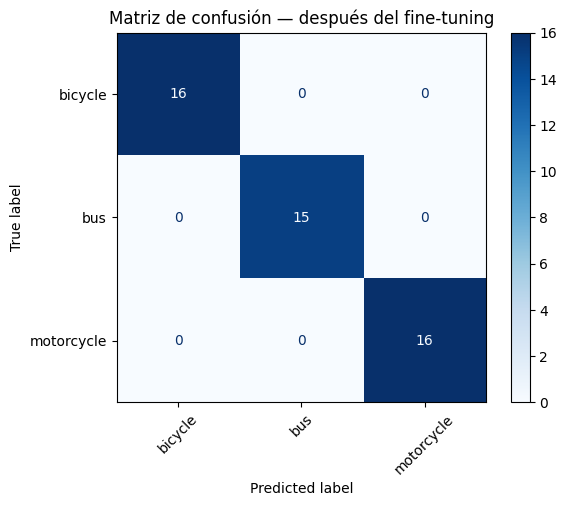

In [21]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

In [24]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

No se encontraron errores en este conjunto.


## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?



## TODO 6 — EN CASA: análisis de errores y conclusiones

### Análisis de errores

Después del fine-tuning, el modelo clasificó correctamente las
**47 imágenes de prueba**: 16 bicicletas, 15 buses y 16 motocicletas.

La matriz de confusión no presenta valores fuera de la diagonal
y la función `show_mistakes` mostró:
“No se encontraron errores en este conjunto”.

Por tanto, no existen cinco errores disponibles para completar
la tabla. Registro esta limitación en lugar de inventar casos.
El resultado no significa que el modelo nunca falle: el conjunto
de prueba es pequeño y puede no representar todas las situaciones
que aparecerían en imágenes nuevas.

### 1. ¿Qué aprendiste al construir el dataset?

Aprendí que descargar imágenes no garantiza obtener un dataset
de calidad. Es necesario comprobar que los archivos se puedan
leer, revisar que correspondan a sus clases y buscar duplicados
o diferencias de estilo que puedan introducir sesgos.

También aprendí a separar los datos en entrenamiento, validación
y prueba, porque cada conjunto cumple una función diferente.

### 2. ¿Cuál fue el principal problema de calidad?

En la muestra inspeccionada, el problema más visible fue la
presencia de marcas de agua y texto de bancos de imágenes.
También observé imágenes con apariencia de ilustración o render.

Estos elementos pueden introducir patrones ajenos al vehículo
que queremos reconocer. La validación técnica encontró cero
archivos inválidos, pero eso no garantiza su calidad visual.

### 3. ¿Cuánto cambió el desempeño después del fine-tuning?

Según la comparación de esta ejecución, el accuracy de prueba
fue de **100 % antes y después del fine-tuning**. El cambio fue
de **0 puntos porcentuales**.

Después del ajuste, precision, recall y F1-score fueron de
**1.000 para las tres clases**.

### 4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?

No produjo una mejora observable en el accuracy de prueba,
porque el modelo ya clasificaba correctamente todas sus imágenes.

Durante el fine-tuning, el accuracy de validación permaneció en
**97.62 %**, mientras que la pérdida de validación disminuyó de
**0.0975 a 0.0868** entre la primera y la quinta época. Esto indica
una mejora en la pérdida durante esa etapa, aunque no aumentó
la proporción de aciertos.

Con estos resultados no puedo afirmar que el fine-tuning mejore
la generalización a todas las imágenes nuevas.

### 5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

Primero mejoraría los datos: revisaría las marcas de agua,
las imágenes artificiales y los posibles duplicados, y aumentaría
la diversidad de fotografías de entrenamiento.

Incluiría distintos ángulos, fondos, condiciones de iluminación
y vehículos parcialmente ocultos. Antes de cambiar la arquitectura,
comprobaría estas mejoras mediante validación.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

Saving 74e894fcd7d2a0c4f10baf1415a9c2558a3b3abb_ElectricScooters_Bike_484717_01.jpg to 74e894fcd7d2a0c4f10baf1415a9c2558a3b3abb_ElectricScooters_Bike_484717_01.jpg


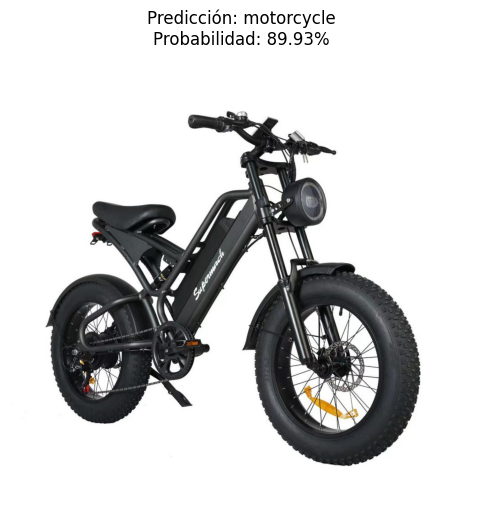

Probabilidades por clase:
bicycle: 9.87%
bus: 0.20%
motorcycle: 89.93%


In [26]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

img = Image.open(
    io.BytesIO(uploaded[filename])
).convert("RGB")

img_resized = img.resize(IMG_SIZE)
x = np.array(img_resized, dtype="float32")[None, ...]

probabilities_external = model.predict(x, verbose=0)[0]
predicted_class = int(np.argmax(probabilities_external))

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicción: {class_names[predicted_class]}\n"
    f"Probabilidad: {probabilities_external[predicted_class]:.2%}"
)
plt.show()

print("Probabilidades por clase:")
for class_name, probability in zip(
    class_names, probabilities_external
):
    print(f"{class_name}: {probability:.2%}")

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.


### Feature extraction / transfer learning con base congelada

Consiste en reutilizar una red que ya aprendió características visuales
en un conjunto grande de imágenes. En mi taller, ese conocimiento
proviene de los pesos de EfficientNetB0 entrenados en ImageNet.

La base permanece congelada: sus parámetros no cambian. Solo se
aprenden los pesos y sesgos de la nueva capa de clasificación para
distinguir bicicletas, buses y motocicletas.

### Fine-tuning

Consiste en adaptar parte del conocimiento de la red preentrenada
a nuestro problema. Además del clasificador, se actualizan los
parámetros de algunas capas finales de la base.

En mi experimento seleccioné las últimas 20 capas y mantuve
BatchNormalization congelada, por lo que quedaron 15 capas
entrenables en la base. Utilicé una tasa de aprendizaje pequeña
para ajustar sus pesos sin cambiar bruscamente lo aprendido.

### Entrenar una CNN desde cero

Consiste en comenzar con pesos inicializados aleatoriamente,
sin reutilizar el conocimiento de una red preentrenada.

Se aprenden todos los parámetros entrenables de la CNN, tanto
los filtros que detectan características como el clasificador,
utilizando únicamente los datos de nuestra tarea. Por eso suele
requerir más imágenes y tiempo de entrenamiento.

**Lo que comprendí:** con la base congelada reutilizo características
y aprendo un clasificador; con fine-tuning también adapto parte
de esas características; desde cero debo aprender ambas cosas.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

**Reto elegido: D. Ablation — sin data augmentation**

Entrenaré un modelo sin aumentación de datos y lo compararé con
el primer modelo de base congelada.

Mantendré el mismo dataset, división, backbone, cabeza de
clasificación, optimizador y configuración de entrenamiento.
La única diferencia será eliminar las transformaciones de
data augmentation.

Compararé los resultados de validación, sin utilizar test
para tomar decisiones de entrenamiento.

In [27]:
keras.utils.set_random_seed(SEED)

base_no_aug = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
)
base_no_aug.trainable = False

inputs_no_aug = keras.Input(shape=(*IMG_SIZE, 3))

# Única diferencia: no se aplica data_augmentation.
x = base_no_aug(inputs_no_aug, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs_no_aug = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
)(x)

model_no_aug = keras.Model(inputs_no_aug, outputs_no_aug)

model_no_aug.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_no_aug = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_no_aug = model_no_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping_no_aug],
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 58s 5s/step - accuracy: 0.4706 - loss: 1.0548 - val_accuracy: 0.9286 - val_loss: 0.6456
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.9216 - loss: 0.5440 - val_accuracy: 1.0000 - val_loss: 0.3155
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.9804 - loss: 0.2911 - val_accuracy: 1.0000 - val_loss: 0.1753
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9951 - loss: 0.1705 - val_accuracy: 1.0000 - val_loss: 0.1148
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9951 - loss: 0.1204 - val_accuracy: 0.9762 - val_loss: 0.0872
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.9853 - loss: 0.1045 - val_accuracy: 0.9762 - val_loss: 0.0732
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.9853 - loss: 0.0880 - val_accuracy: 0.9762 - val_loss: 0.0648
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9902 - loss: 0.0714 - val_accuracy: 0.9762 - val_loss: 0.0592
Epoch 9/

In [28]:
best_with_aug = int(np.argmin(history.history["val_loss"]))
best_without_aug = int(np.argmin(history_no_aug.history["val_loss"]))

print("Con data augmentation:")
print(
    f"Val accuracy: "
    f"{history.history['val_accuracy'][best_with_aug]:.2%}"
)
print(
    f"Val loss: "
    f"{history.history['val_loss'][best_with_aug]:.4f}"
)

print("\nSin data augmentation:")
print(
    f"Val accuracy: "
    f"{history_no_aug.history['val_accuracy'][best_without_aug]:.2%}"
)
print(
    f"Val loss: "
    f"{history_no_aug.history['val_loss'][best_without_aug]:.4f}"
)

Con data augmentation:
Val accuracy: 97.62%
Val loss: 0.1009

Sin data augmentation:
Val accuracy: 97.62%
Val loss: 0.0526


# ✅ Checklist de entrega

### Evidencia del trabajo en clase

- [x] Problema y clases definidos.
- [x] Dataset construido y revisado mediante muestras; limitaciones de calidad documentadas.
- [x] Train / validation / test creados.
- [x] Primer modelo con backbone congelado entrenado.

### Trabajo en casa

- [x] Evaluación sobre test.
- [x] Matriz de confusión.
- [x] Precision / recall / F1 interpretados.
- [x] Fine-tuning ejecutado.
- [x] Comparación antes vs. después del fine-tuning reportada.
- [X] Al menos 5 errores analizados: no hubo errores en las 47 imágenes de test; esta limitación quedó documentada.
- [x] Conclusión final escrita.

### Opcional

- [X] Imagen externa: código preparado; falta confirmar la predicción obtenida.
- [X] Experimento adicional / reto: código preparado; falta confirmar la ejecución y completar la comparación.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |